## Imports

In [1]:
import requests
from dotenv import load_dotenv
import pandas as pd
import os
import numpy as np

## Phase 1: API Extraction

In [2]:
load_dotenv()
API_KEY= os.getenv("TMDB_API_KEY")

In [28]:
movie_ids = [299534, 19995, 140607, 299536, 18, 95, 59967, 680, 24, 393, 597, 135397, 424, 259316, 24428, 1726, 283995, 118340, 168259, 76341, 209112, 271110, 120, 680, 559]

base_url = "https://api.themoviedb.org/3/movie/"
movies_data= []

for movie_id in movie_ids:

    url= f"{base_url}{movie_id}?api_key={API_KEY}"
    response= requests.get(url)

    if response.status_code == 200:
        movies_data.append(response.json())
    else:
        print(f"Failed to Fetch ID {movie_id}: {response.status_code}")


df= pd.DataFrame(movies_data)

df.head(2)

,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,original_language,...,revenue,runtime,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,/7RyHsO4yDXtBv1zUU3mTpHeQ0d5.jpg,"{'id': 86311, 'name': 'The Avengers Collection...",356000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 878, ...",https://www.marvel.com/movies/avengers-endgame,299534,tt4154796,[US],en,...,2927449455,181,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Avenge the fallen.,Avengers: Endgame,False,8.246,29005
1,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,"{'id': 87096, 'name': 'Avatar Collection', 'po...",237000000,"[{'id': 878, 'name': 'Science Fiction'}, {'id'...",https://www.avatar.com/movies/avatar,19995,tt0499549,[US],en,...,2923706026,162,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Enter the world of Pandora.,Avatar,False,7.611,34845


## Phase 2 Data Cleaning

In [29]:
import ast

def extract_names(json_data):



    try:

        if isinstance(json_data, list):
            return "|".join([item['name'] for item in json_data])

        elif isinstance(json_data,str):
            json_data= ast.literal_eval(json_data)

        else:
            return ""

        names= [item['name'] for item in json_data]

        return "|".join(names)
    
    except:
        return ""


df['genres']= df['genres'].apply(extract_names)
df['production_companies']= df['production_companies'].apply(extract_names)

df[['title', 'genres', 'production_companies']].head()
    

,title,genres,production_companies
0,Avengers: Endgame,Adventure|Science Fiction|Action,Marvel Studios
1,Avatar,Science Fiction|Action|Adventure,Dune Entertainment|Lightstorm Entertainment|20...
2,Star Wars: The Force Awakens,Adventure|Action|Science Fiction,Lucasfilm Ltd.|Bad Robot
3,Avengers: Infinity War,Adventure|Action|Science Fiction,Marvel Studios
4,The Fifth Element,Science Fiction|Action|Adventure,Gaumont


In [ ]:
df['budget']= pd.to_numeric(df['budget'], errors='coerce')
df['revenue']= pd.to_numeric(df['revenue'], errors='coerce')

df['budget_musd'] = df['budget'] / 1000000
df['revenue_musd'] = df['revenue'] / 1000000

df[['title', 'budget_musd', 'revenue_musd']].head()

,title,budget_musd,revenue_musd
0,Avengers: Endgame,356.0,2927.449455
1,Avatar,237.0,2923.706026
2,Star Wars: The Force Awakens,245.0,2068.223624
3,Avengers: Infinity War,300.0,2052.415039
4,The Fifth Element,90.0,263.920180


In [31]:
columns_to_drop = ['adult', 'imdb_id', 'original_title', 'video', 'homepage']
df.drop(columns=columns_to_drop, errors="ignore", inplace= True)
df= df[df['status']== 'Released'].copy()
df.drop(columns=['status'], inplace= True)

df['release_date']= pd.to_datetime(df['release_date'], errors="coerce")
df[['title','release_date']].head()

,title,release_date
0,Avengers: Endgame,2019-04-24
1,Avatar,2009-12-16
2,Star Wars: The Force Awakens,2015-12-15
3,Avengers: Infinity War,2018-04-25
4,The Fifth Element,1997-05-02


In [32]:
df[['budget', 'revenue', 'runtime']]= df[['budget', 'revenue', 'runtime']].replace(0, np.nan)
df['spoken_languages'] = df['spoken_languages'].apply(extract_names)
df['production_countries'] = df['production_countries'].apply(extract_names)


def get_collection_name(json_data):
    try:
        if isinstance(json_data, dict):
            return json_data.get('name','')
        elif isinstance(json_data,str):
            parsed= ast.literal_eval(json_data)
            return parsed.get('name','')
        else:
            return ""
    except:
        return ""

df['belongs_to_collection']= df['belongs_to_collection'].apply(get_collection_name)
df['belongs_to_collection'].head()

0    The Avengers Collection
1          Avatar Collection
2       Star Wars Collection
3    The Avengers Collection
4                           
Name: belongs_to_collection, dtype: str

In [33]:
df.dropna(thresh=10, inplace=True)

df.drop_duplicates(subset=['id'] ,inplace=True)

final_order = [
    'id', 'title', 'tagline', 'release_date', 'genres', 'belongs_to_collection',
    'original_language', 'budget_musd', 'revenue_musd', 'production_companies',
    'production_countries', 'vote_count', 'vote_average', 'popularity', 'runtime',
    'overview', 'spoken_languages', 'poster_path'
]

existing_columns= [col for col in final_order if col in df.columns]
df= df[existing_columns]

df.reset_index( drop = True,inplace= True)

df.head(2)

,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,production_countries,vote_count,vote_average,popularity,runtime,overview,spoken_languages,poster_path
0,299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.0,2927.449455,Marvel Studios,United States of America,29005,8.246,87.1502,181,After the devastating events of Avengers: Infi...,English|日本語|,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg
1,19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.0,2923.706026,Dune Entertainment|Lightstorm Entertainment|20...,United States of America|United Kingdom,34845,7.611,48.3380,162,"In the 22nd century, a paraplegic Marine is di...",English|Español,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg


## Phase 3 KPI Implementation & Analysis

In [34]:
df['profit_musd']= df['revenue_musd'] - df['budget_musd']
df['roi']= df['revenue_musd'] / df['budget_musd']

def rank_movies(dataframe, metric_column, ascending=False, min_budget=0 , min_vote=0, top_n=5):
    """
    Ranks movies based on a specific metric, applying optional filters for budget and votes.
    """

    filtered_df= dataframe[
        (dataframe['budget_musd'].fillna(0) >= min_budget) &
        (dataframe['vote_count'].fillna(0) >=  min_vote)
    ]

    ranked_df= filtered_df.sort_values(by=metric_column, ascending=ascending)

    return ranked_df[['title', metric_column, 'budget_musd', 'vote_count']].head(top_n)

print("--- Highest Revenue ---")
display(rank_movies(df, 'revenue_musd'))

print("\n--- Highest ROI (Budget >= 10M) ---")
display(rank_movies(df, 'roi', min_budget=10))

print("\n--- Lowest Profit ---")

display(rank_movies(df, 'profit_musd', ascending=True))

print("\n--- Highest Rated (Votes >= 10) ---")
display(rank_movies(df, 'vote_average', min_vote=10))


--- Highest Revenue ---


,title,revenue_musd,budget_musd,vote_count
0,Avengers: Endgame,2927.449455,356.0,29005
1,Avatar,2923.706026,237.0,34845
10,Titanic,2264.162353,200.0,27901
2,Star Wars: The Force Awakens,2068.223624,245.0,21013
3,Avengers: Infinity War,2052.415039,300.0,33148



--- Highest ROI (Budget >= 10M) ---


,title,roi,budget_musd,vote_count
12,Schindler's List,14.607526,22.0,18036
1,Avatar,12.336312,237.0,34845
10,Titanic,11.320812,200.0,27901
11,Jurassic World,11.143583,150.0,22008
22,The Lord of the Rings: The Fellowship of the Ring,9.369552,93.0,28586



--- Lowest Profit ---


,title,profit_musd,budget_musd,vote_count
6,Looper,17.042000,30.0,11271
9,Kill Bill: Vol. 2,122.159461,30.0,15549
8,Kill Bill: Vol. 1,150.906076,30.0,19563
4,The Fifth Element,173.920180,90.0,12246
7,Pulp Fiction,205.928762,8.0,31084



--- Highest Rated (Votes >= 10) ---


,title,vote_average,budget_musd,vote_count
12,Schindler's List,8.600,22.0,18036
7,Pulp Fiction,8.480,8.0,31084
22,The Lord of the Rings: The Fellowship of the Ring,8.447,93.0,28586
0,Avengers: Endgame,8.246,356.0,29005
3,Avengers: Infinity War,8.245,300.0,33148


In [35]:
credits_data= []

print("Fetching missing credits from TMDB...")

for movie_id in  df['id']:
    url = f"https://api.themoviedb.org/3/movie/{movie_id}/credits?api_key={API_KEY}"
    response= requests.get(url)

    if response.status_code== 200:
        res_json= response.json()

        cast_list= [actor['name'] for actor in res_json.get('cast',[])]
        cast_str= "|".join(cast_list)

        director_list= [director['name'] for director in res_json.get('crew', []) if director.get('job')== 'Director']
        director_str= "|".join(director_list)

        credits_data.append({
            'id': movie_id,
            'cast':cast_str,
            'director': director_str
        })

credits_df= pd.DataFrame(credits_data)
df= df.merge(credits_df, on='id', how='left')

print("Success! 'cast' and 'director' columns added.")
df[['title', 'cast', 'director']].head(2)

Fetching missing credits from TMDB...
Success! 'cast' and 'director' columns added.


,title,cast,director
0,Avengers: Endgame,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,Anthony Russo|Joe Russo
1,Avatar,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,James Cameron


In [38]:

bruce_scifi= df[
    (df['genres'].str.contains("Science Fiction", na=False))&
    (df['genres'].str.contains("Action" , na=False))&
    (df['cast'].str.contains("Bruce Willis", na=False))
]
bruce_ranked= bruce_scifi.sort_values(by='vote_average', ascending=False)
print("--- Bruce Willis Sci-Fi Action ---")
display(bruce_ranked[['title', 'vote_average', 'genres']])

uma_tarantino = df[
    (df['cast'].str.contains('Uma Thurman', na=False)) & 
    (df['director'].str.contains('Quentin Tarantino', na=False))
]

uma_tarantino_ranked = uma_tarantino.sort_values(by='runtime', ascending=True)
print("\n--- Uma Thurman & Quentin Tarantino ---")
display(uma_tarantino_ranked[['title', 'runtime', 'director']])

--- Bruce Willis Sci-Fi Action ---


,title,vote_average,genres
4,The Fifth Element,7.593,Science Fiction|Action|Adventure
6,Looper,6.917,Action|Thriller|Science Fiction
5,Armageddon,6.833,Action|Science Fiction|Adventure



--- Uma Thurman & Quentin Tarantino ---


,title,runtime,director
8,Kill Bill: Vol. 1,111,Quentin Tarantino
9,Kill Bill: Vol. 2,136,Quentin Tarantino
7,Pulp Fiction,154,Quentin Tarantino


In [43]:
df['franchise_status']= np.where(df["belongs_to_collection"] == '', 'Standlone', 'Franchise')

franchise_comparison= df.groupby('franchise_status').agg({
    'revenue_musd': 'mean',
    'roi': 'median',
    'budget_musd':'mean',
    'popularity':'mean',
    'vote_average': 'mean'
}).round(2)

franchise_comparison.rename(columns={
    'revenue_musd': 'Mean Revenue (M)',
    'roi': 'Median ROI',
    'budget_musd': 'Mean Budget (M)',
    'popularity': 'Mean Popularity',
    'vote_average': 'Mean Rating'
}, inplace=True)

print("--- Franchise vs. Standalone Performance ---")
display(franchise_comparison)

--- Franchise vs. Standalone Performance ---


,Mean Revenue (M),Median ROI,Mean Budget (M),Mean Popularity,Mean Rating
franchise_status,,,,,
Franchise,1234.24,5.55,191.61,52.45,7.54
Standlone,610.70,7.64,81.67,45.96,7.72


In [44]:

franchises_only = df[
    (df['belongs_to_collection'] != '') & 
    (df['belongs_to_collection'].notna())
].copy()


franchise_summary = franchises_only.groupby('belongs_to_collection').agg(
    movie_count=('title', 'count'),
    total_budget_musd=('budget_musd', 'sum'),
    mean_budget_musd=('budget_musd', 'mean'),
    total_revenue_musd=('revenue_musd', 'sum'),
    mean_revenue_musd=('revenue_musd', 'mean'),
    mean_rating=('vote_average', 'mean')
).round(2)


top_franchises = franchise_summary.sort_values(by='total_revenue_musd', ascending=False)

print("--- Top Movie Franchises by Total Revenue ---")
display(top_franchises.head(10))

--- Top Movie Franchises by Total Revenue ---


,movie_count,total_budget_musd,mean_budget_musd,total_revenue_musd,mean_revenue_musd,mean_rating
belongs_to_collection,,,,,,
The Avengers Collection,3,876.0,292.0,6498.68,2166.23,8.19
Avatar Collection,1,237.0,237.0,2923.71,2923.71,7.61
Star Wars Collection,1,245.0,245.0,2068.22,2068.22,7.20
Jurassic Park Collection,1,150.0,150.0,1671.54,1671.54,6.70
Guardians of the Galaxy Collection,2,370.0,185.0,1636.53,818.27,7.76
The Fast and the Furious Collection,1,190.0,190.0,1515.40,1515.40,7.21
Captain America Collection,1,250.0,250.0,1155.05,1155.05,7.45
Spider-Man Collection,1,258.0,258.0,894.98,894.98,6.48
Man of Steel Collection,1,250.0,250.0,874.36,874.36,6.01


In [46]:

directors_df = df[df['director'].notna() & (df['director'] != '')].copy()
directors_df = directors_df.assign(director=directors_df['director'].str.split('|')).explode('director')


director_summary = directors_df.groupby('director').agg(
    total_movies=('title', 'count'),
    total_revenue_musd=('revenue_musd', 'sum'),
    mean_rating=('vote_average', 'mean')
).round(2)


top_directors_revenue = director_summary.sort_values(by='total_revenue_musd', ascending=False)

print("--- Top Directors by Total Revenue ---")
display(top_directors_revenue.head(10))


multi_movie_directors = director_summary[director_summary['total_movies'] >= 2]
top_directors_rating = multi_movie_directors.sort_values(by='mean_rating', ascending=False)

print("\n--- Top Directors by Mean Rating (Minimum 2 Movies) ---")
display(top_directors_rating.head(10))

--- Top Directors by Total Revenue ---


,total_movies,total_revenue_musd,mean_rating
director,,,
Anthony Russo,3,6134.91,7.98
Joe Russo,3,6134.91,7.98
James Cameron,2,5187.87,7.76
J.J. Abrams,1,2068.22,7.20
Colin Trevorrow,1,1671.54,6.70
James Gunn,2,1636.53,7.76
Joss Whedon,1,1518.82,8.08
James Wan,1,1515.40,7.21
Sam Raimi,1,894.98,6.48



--- Top Directors by Mean Rating (Minimum 2 Movies) ---


,total_movies,total_revenue_musd,mean_rating
director,,,
Quentin Tarantino,3,546.99,8.11
Anthony Russo,3,6134.91,7.98
Joe Russo,3,6134.91,7.98
James Gunn,2,1636.53,7.76
James Cameron,2,5187.87,7.76


## Final 4: Data Visualization

In [48]:
df.to_csv('data/tmdb_movies_clean.csv', index=False)
print("Success! Clean dataset exported to data/tmdb_movies_clean.csv")

Success! Clean dataset exported to data/tmdb_movies_clean.csv


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")



## 4.1: Revenue vs. Budget Trends

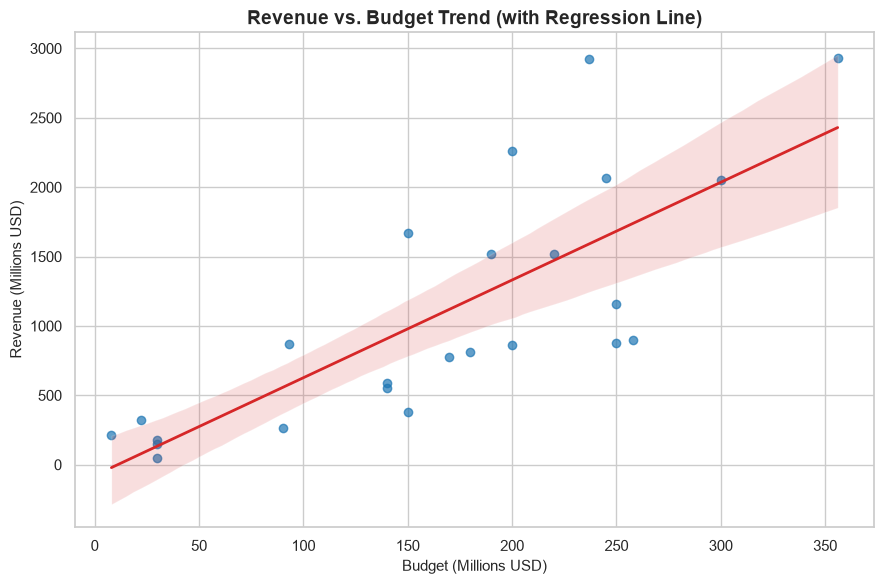

In [54]:
plt.figure(figsize=(9, 6))
sns.regplot(
    data=df,
    x='budget_musd',
    y='revenue_musd',
    scatter_kws={'alpha': 0.7, 'color': '#1f77b4'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)
plt.title('Revenue vs. Budget Trend (with Regression Line)', fontsize=14, fontweight='bold')
plt.xlabel('Budget (Millions USD)', fontsize=11)
plt.ylabel('Revenue (Millions USD)', fontsize=11)
plt.tight_layout()
plt.show()


## 4.2. ROI Distribution by Genre

C:\Users\KING\AppData\Local\Temp\ipykernel_14688\3959196119.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


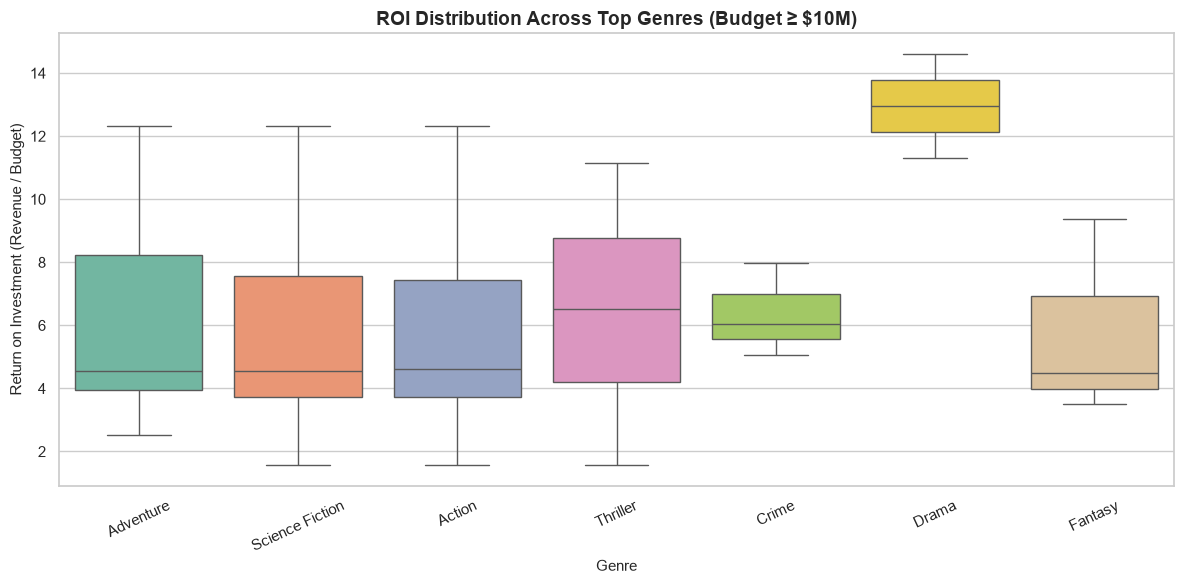

In [55]:

df_genres = df.assign(genre=df['genres'].str.split('|')).explode('genre')
df_genres = df_genres[df_genres['genre'].str.strip() != '']


top_genres = df_genres['genre'].value_counts().head(8).index
filtered_genres = df_genres[
    (df_genres['genre'].isin(top_genres)) & 
    (df_genres['budget_musd'] >= 10) & 
    (df_genres['roi'].notna())
]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=filtered_genres,
    x='genre',
    y='roi',
    palette='Set2'
)
plt.title('ROI Distribution Across Top Genres (Budget ≥ $10M)', fontsize=14, fontweight='bold')
plt.xlabel('Genre', fontsize=11)
plt.ylabel('Return on Investment (Revenue / Budget)', fontsize=11)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 4.3. Popularity vs. Rating

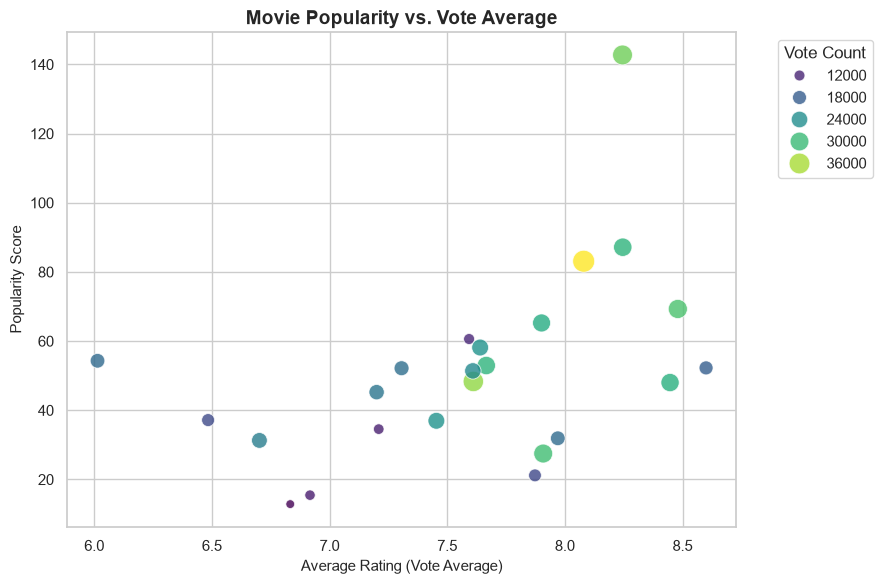

In [72]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='vote_average',
    y='popularity',
    hue='vote_count',
    size='vote_count',
    sizes=(40, 250),
    palette='viridis',
    alpha=0.8
)
plt.title('Movie Popularity vs. Vote Average', fontsize=14, fontweight='bold')
plt.xlabel('Average Rating (Vote Average)', fontsize=11)
plt.ylabel('Popularity Score', fontsize=11)
plt.legend(title='Vote Count', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 4.4. Yearly Trends in Box Office Performance

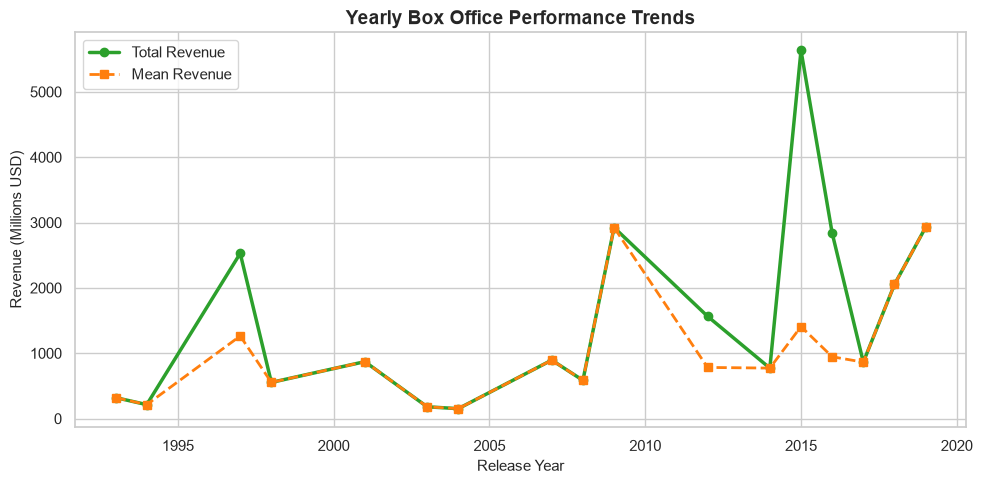

In [57]:

df['release_year'] = df['release_date'].dt.year
yearly_box_office = df.dropna(subset=['release_year']).groupby('release_year').agg(
    total_revenue=('revenue_musd', 'sum'),
    mean_revenue=('revenue_musd', 'mean')
).reset_index()

plt.figure(figsize=(10, 5))
plt.plot(yearly_box_office['release_year'], yearly_box_office['total_revenue'], marker='o', linewidth=2.5, color='#2ca02c', label='Total Revenue')
plt.plot(yearly_box_office['release_year'], yearly_box_office['mean_revenue'], marker='s', linestyle='--', linewidth=2, color='#ff7f0e', label='Mean Revenue')

plt.title('Yearly Box Office Performance Trends', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=11)
plt.ylabel('Revenue (Millions USD)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Comparison of Franchise vs. Standalone Success

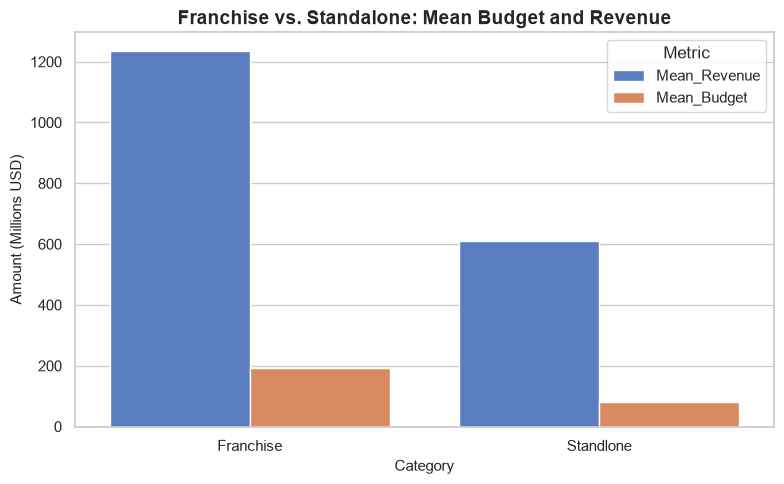

In [58]:

if 'franchise_status' not in df.columns:
    df['franchise_status'] = np.where(
        (df['belongs_to_collection'] == '') | (df['belongs_to_collection'].isna()),
        'Standalone',
        'Franchise'
    )

comparison_metrics = df.groupby('franchise_status').agg(
    Mean_Revenue=('revenue_musd', 'mean'),
    Mean_Budget=('budget_musd', 'mean')
).reset_index()


melted_comp = comparison_metrics.melt(
    id_vars='franchise_status',
    value_vars=['Mean_Revenue', 'Mean_Budget'],
    var_name='Metric',
    value_name='Millions_USD'
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=melted_comp,
    x='franchise_status',
    y='Millions_USD',
    hue='Metric',
    palette='muted'
)
plt.title('Franchise vs. Standalone: Mean Budget and Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Category', fontsize=11)
plt.ylabel('Amount (Millions USD)', fontsize=11)
plt.tight_layout()
plt.show()